<div class="alert alert-block alert-info">
¡Hola! Denisse ¿Cómo estás? Mi nombre es Santiago, ¡un gusto conocerte! 😊

Cuando encuentre un error por primera vez, lo señalaré para que lo corrijas por tu cuenta. Si en la siguiente iteración no lo resuelves, te daré una pista más concreta.

Por favor, <b>no muevas ni elimines</b> mis comentarios.

</div>

<div class="alert alert-block alert-success">✅ Éxito.</div>
<div class="alert alert-block alert-warning">⚠️ Observación menor.</div>
<div class="alert alert-block alert-danger">❌ Necesita corrección. No puede aprobarse con comentarios rojos.</div>


<div class="alert alert-block alert-danger">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a>

¡Hola! Este es uno de los proyectos más limpios y completos que he revisado en este sprint. Quiero felicitarte sinceramente por el nivel del trabajo.

**Lo que está muy bien hecho:**
- Convertiste `date` a datetime antes del `describe()` — orden correcto.
- Revisaste todas las variables categóricas en el EDA y mostraste el `describe()` filtrado a usuarios convertidos.
- Usaste `equal_var=False` en el t-test — elección correcta.
- Incluiste las tablas normalizadas (tasas) tanto para `traffic_source` como para `user_type` antes de cada chi-cuadrada — excelente práctica.
- El Paso 6 tiene los cuatro gráficos completos: absoluto + proporción para ambas variables.
- La interpretación de canales es correcta: identificas que Email (14.99%) y Ads (14.74%) tienen las mejores tasas, mientras que Organic domina en volumen pero no en eficiencia.
- El Insight Ejecutivo es de nivel profesional: cita los valores concretos, interpreta cada hallazgo correctamente y cierra con dos recomendaciones accionables.
- Ejecución limpia y secuencial (1→35).

**Un único punto a corregir antes de aprobar:**

En el Paso 2 falta la **prueba de Levene** antes del t-test. Usaste `equal_var=False` (Welch), que es la elección correcta — pero esa elección debe respaldarse con la prueba de Levene, que verifica estadísticamente si las varianzas de los dos grupos son efectivamente diferentes. Agrégala antes del t-test.

**Observaciones menores (no bloquean):**
- Los encabezados de hipótesis dicen "### Prueba ..." en los cuatro pasos — completa el nombre: "Prueba t de Welch", "Prueba Z de proporciones", "Prueba Chi-cuadrada".
- En las hipótesis, el marcador de negrita está abierto pero no cerrado: `**Hipótesis nula (H₀): ...` debería ser `**Hipótesis nula (H₀):** ...`
- Los imports estadísticos están dispersos dentro de las celdas. Te recomiendo agruparlos todos en la celda 2 junto a `pandas`.
- En la celda 20, `.apply(pd.Series.value_counts)` funciona pero genera una tabla ancha con muchos NaN — un bucle `for col in columnas: print(df[col].value_counts())` es más legible.
- Typo en la celda 29: "difere]ncias" — hay un `]` en "diferencias".

¡Con solo agregar la prueba de Levene, el proyecto queda aprobado. Excelente trabajo!
</div>

<div class="alert alert-block alert-success">
<b>Review General. (Iteración 2)</b> <a class="tocSkip"></a>

¡Hola de nuevo! Revisé tu segunda entrega verificando cada punto con código crudo y outputs reales. El resultado habla por sí solo.

**Todo corregido — incluyendo cada uno de los puntos amarillos:**

- ✅ **Prueba de Levene (punto rojo):** Importaste `levene` junto al resto de librerías en la celda 3, la aplicaste correctamente en la celda 33 (Estadístico = 29.176, p = 0.00000 → varianzas diferentes → `equal_var=False` justificado), escribiste la conclusión de Levene en la celda 34, y referenciaste ese resultado en la conclusión del Paso 2 (celda 36). Flujo estadístico impecable.
- ✅ **Encabezados de hipótesis:** Los cuatro pasos ahora tienen el nombre completo de la prueba ("Prueba t de Welch", "Prueba Z de proporciones", "Prueba Chi-cuadrada").
- ✅ **Marcadores de negrita H₀/H₁:** Corregidos en las cuatro celdas — ahora cierran correctamente con `**Hipótesis nula (H₀):**`.
- ✅ **Imports agrupados:** Todos en la celda 3 (`ttest_ind`, `levene`, `chi2_contingency`, `proportions_ztest`).
- ✅ **Typo "difere]ncias":** Corregido en la celda de contexto del Paso 3.
- ✅ **EDA con bucle:** La celda 25 ahora usa `for col in columnas:` en lugar de `.apply(pd.Series.value_counts)` — mucho más legible.

No hay puntos rojos ni amarillos. Este fue un proyecto excelente desde la primera iteración, y en esta segunda entrega demostraste atención al detalle al corregir hasta el último punto.

**¡Felicitaciones, tu proyecto está aprobado!** 🎉 Mucho éxito en los siguientes sprints.

Saludos.
</div>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [2]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    ttest_ind,
    levene,
    chi2_contingency
)

from statsmodels.stats.proportion import proportions_ztest

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 2)</b> <a class="tocSkip"></a>

✅ ¡Perfecto! Todos los imports ahora están agrupados en una sola celda al inicio, incluyendo `levene`. Muy buena organización.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

⚠️ Solo tienes `pandas` al inicio. Para un notebook más organizado y profesional, agrupa aquí todos los imports que usas a lo largo del análisis:

```python
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, levene, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
```

Así queda todo visible desde el principio y no necesitas reimportar dentro de las celdas de análisis.
</div>

In [3]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [4]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [5]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**

El conjunto de datos contiene 40,000 registros y 9 columnas, correspondientes a información de usuarios que participaron en un experimento A/B sobre una página de inicio.

No se observan valores ausentes en ninguna de las columnas, por lo que el dataset está completo y puede utilizarse para el análisis sin necesidad de realizar imputaciones o eliminar registros.

Las variables presentan tipos de datos adecuados en su mayoría. Sin embargo, la columna date está almacenada como tipo object, por lo que es recomendable convertirla al tipo datetime para facilitar el análisis temporal del experimento.

En general, el dataset presenta una buena calidad de datos y es apto para continuar con el análisis estadístico.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [6]:
# Verificar usuarios únicos
print("Usuarios únicos:", df["user_id"].nunique())
print("Total de registros:", len(df))

Usuarios únicos: 40000
Total de registros: 40000


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Correcto, 40,000 usuarios únicos sin duplicados.
</div>

 **Variable `date`**  
Explorar rango de fechas

In [7]:
# Convertir date a fecha
df["date"] = pd.to_datetime(df["date"])


In [8]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [9]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ ¡Muy bien! Convertiste `date` a datetime (celda 13) antes de ejecutar `describe()` y `min/max` — ese es el orden correcto.
</div>

**Variable `gasto` (numérica)**

In [10]:
# Resumen estadístico
print(df["gasto"].describe())

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64


In [11]:
# Resumen estadístico de usuarios que se convirtieron
print(df[df["converted"] == 1]["gasto"].describe())

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Excelente: mostraste el `describe()` general Y el filtrado a usuarios convertidos (media = $65.37). Eso da una imagen real del gasto de quienes sí compraron.
</div>

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [12]:
# Explorar variables categóricas y cómo se distribuyen
columnas = [
    "landing",
    "region",
    "dispositivo",
    "traffic_source",
    "user_type"
]

for col in columnas:
    print(f"\n{col}")
    print(df[col].value_counts()) #completa el código)


landing
B    20018
A    19982
Name: landing, dtype: int64

region
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 2)</b> <a class="tocSkip"></a>

✅ ¡Corregido! El EDA ahora usa un bucle limpio para revisar las variables categóricas — mucho más legible que el método anterior.
</div>

✍️ **Comentario**

La revisión de calidad muestra que cada registro corresponde a un usuario único, por lo que no se detectan duplicados en la columna user_id.

El experimento cuenta con dos versiones de la página (A y B) con una distribución prácticamente equilibrada, lo que favorece una comparación estadística confiable entre ambos grupos.

Las variables categóricas presentan únicamente categorías esperadas y no se observan valores atípicos o etiquetas mal escritas. Asimismo, la variable gasto contiene valores numéricos válidos, considerando que los usuarios que no realizaron una conversión presentan un gasto de 0, comportamiento esperado según la descripción del dataset.

En general, los datos son consistentes y cumplen con las condiciones necesarias para continuar con el análisis del experimento A/B.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Revisaste todas las variables categóricas y el balance A/B está confirmado (~50/50). El comentario es claro.

⚠️ El método `.apply(pd.Series.value_counts)` funciona pero genera una tabla ancha con muchos `NaN` (porque las categorías de cada columna no coinciden entre sí). Te recomiendo un bucle para verlo más limpio:

```python
for col in ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']:
    print(f"\n{col}:\n", df[col].value_counts())
```
</div>

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [13]:
# Gasto por versión
gasto_A = df[(df["landing"] == "A") & (df["converted"] == 1)]["gasto"] #completa el código
gasto_B = df[(df["landing"] == "B") & (df["converted"] == 1)]["gasto"] #completa el código

# Verificar cantidad de datos que tiene cada grupo
print("Usuarios convertidos en A:", len(gasto_A))
print("Usuarios convertidos en B:", len(gasto_B))

Usuarios convertidos en A: 2512
Usuarios convertidos en B: 3194


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Correcto, filtraste por `converted==1` para ambos grupos.
</div>

### Prueba t de Welch

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios convertidos es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios convertidos es diferente entre la página A y la página B.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 2)</b> <a class="tocSkip"></a>

✅ Encabezado completado correctamente. Los cuatro pasos ahora tienen el nombre preciso de la prueba.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Hipótesis bien redactadas en contenido. Dos detalles de formato a corregir:
1. El encabezado dice "### Prueba ..." — reemplázalo por **"### Prueba t de Welch"**.
2. Las H₀ y H₁ tienen el `**` abierto pero no cerrado: `**Hipótesis nula (H₀): ...` → `**Hipótesis nula (H₀):** ...`

Estos mismos detalles se repiten en los Pasos 3, 4 y 5.
</div>

In [14]:
# Prueba de Levene
stat_levene, p_levene = levene(gasto_A, gasto_B)


# Visualizar resultados
print(f"Estadístico de Levene: {stat_levene:.3f}")
print(f"Valor p: {p_levene:.5f}")

Estadístico de Levene: 29.176
Valor p: 0.00000


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 2)</b> <a class="tocSkip"></a>

✅ ¡Corregido! Levene correctamente aplicada (Estadístico = 29.176, p = 0.00000 → varianzas diferentes → `equal_var=False` justificado). 👏
</div>

## Conclusion de la prueba Levene
Como el valor p es menor que 0.05, se rechaza la hipótesis nula de igualdad de varianzas. Esto indica que existen diferencias significativas entre las varianzas de ambos grupos, por lo que es apropiado utilizar la prueba t de Welch (equal_var=False) para comparar los promedios de gasto entre las páginas A y B.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 2)</b> <a class="tocSkip"></a>

✅ Excelente: escribiste una conclusión explícita de Levene que justifica el uso de `equal_var=False`. Hace el flujo estadístico muy claro y bien documentado.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

❌ Aplicaste `equal_var=False` (Welch), que es la elección correcta. Sin embargo, esa elección debe justificarse con la **prueba de Levene** previa. Agrégala justo antes de esta celda (junto a sus hipótesis H₀/H₁), como se muestra en el Review General.
</div>

### 📝 Conclusión e interpretación

**Decisión:**  
Como el valor p es mucho menor que 0.05, se rechaza la hipótesis nula

Previamente se aplicó la prueba de Levene para evaluar la igualdad de varianzas entre ambos grupos. Dado que se detectaron diferencias significativas en las varianzas, se utilizó la prueba t de Welch (equal_var=False), la cual es adecuada cuando no puede asumirse igualdad de varianzas.

**Interpretación de negocio:**  
Los resultados muestran que existe una diferencia estadísticamente significativa en el gasto promedio de los usuarios que realizaron una compra entre las páginas A y B.

En este experimento, los usuarios que convirtieron después de ver la página B registraron un gasto promedio mayor que los usuarios de la página A (aproximadamente 68.75 frente a 61.09 unidades monetarias). Esto indica que la versión B no solo favorece las conversiones, sino que también genera un mayor ingreso por cliente convertido.

Desde la perspectiva del negocio, estos resultados sugieren que la página B tiene un mejor desempeño económico y representa una alternativa más atractiva para incrementar los ingresos generados por los usuarios que realizan una compra.

---

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ ¡Excelente conclusión! Mencionas los valores concretos (68.75 vs 61.09) y el argumento de negocio es preciso. Recuerda actualizar para citar también el resultado de Levene cuando lo agregues.
</div>


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

⚠️ Typo: "difere]ncias" — hay un `]` en la palabra "diferencias".
</div>

### Prueba Z de proporciones

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual para la página A y la página B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre la página A y la página B.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Hipótesis correctas. ⚠️ Completa el encabezado: **"### Prueba Z de proporciones"** y cierra los `**` en H₀/H₁.
</div>

In [15]:
# Número de usuarios convertidos por página
convertidos = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", convertidos)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [20]:
# Aplicar prueba Z para dos proporciones
z_stat, p_value = proportions_ztest(
    count=convertidos,
    nobs=totales
)

# Visualizar resultados
print(f"Estadístico : {z_stat:.3f}")
print(f"Valor p: {p_value:.5f}")

Estadístico : -9.677
Valor p: 0.00000


### 📝 Conclusión e interpretación

**Decisión:**  
Como el valor p es menor que 0.05, se rechaza la hipótesis nula.

**Interpretación de negocio:**  
Los resultados indican que existe una diferencia estadísticamente significativa en la tasa de conversión entre las páginas A y B.

La página B obtuvo 3,194 conversiones de 20,018 usuarios, mientras que la página A registró 2,512 conversiones de 19,982 usuarios. Esto equivale aproximadamente a una tasa de conversión de 15.96% para la página B y 12.57% para la página A.

Estos resultados muestran que la página B convierte una mayor proporción de usuarios en clientes. Dado que la diferencia es estadísticamente significativa, existe evidencia suficiente para afirmar que la versión B tiene un mejor desempeño en términos de conversión dentro del experimento realizado.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Prueba Z de proporciones correctamente aplicada. Conclusión con los valores exactos (15.96% vs 12.57%). Muy bien.
</div>

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi-cuadrada

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una asociación entre la fuente de tráfico (traffic_source) y la conversión (converted). La conversión es independiente del canal de tráfico.
- **Hipótesis alternativa (H₁):** Existe una asociación entre la fuente de tráfico (traffic_source) y la conversión (converted)..

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Hipótesis correctas. ⚠️ Completa el encabezado: **"### Prueba Chi-cuadrada"** y cierra los `**`.
</div>

In [21]:
# Tabla de contingencia
tabla_trafico = pd.crosstab(df["traffic_source"], df["converted"])

print(tabla_trafico)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [22]:
# Aplicar prueba Chi-cuadrado
chi2, p_value, dof, expected = chi2_contingency(tabla_trafico)

print(f"Chi-cuadrado: {chi2:.3f}")
print(f"Valor p: {p_value:.5f}")
print(f"Grados de libertad: {dof}")


Chi-cuadrado: 8.662
Valor p: 0.03414
Grados de libertad: 3


In [23]:
# Tasas de conversión por fuente de tráfico
conversion_trafico = pd.crosstab(
    df["traffic_source"],
    df["converted"],
    normalize="index"
) * 100

print(conversion_trafico.round(2))

converted           0      1
traffic_source              
Ads             85.26  14.74
Email           85.01  14.99
Organic         86.21  13.79
Referral        86.12  13.88


In [24]:
# Decision
alpha = 0.05

if p_value < alpha:
    print("Rechazamos la hipótesis nula: existe asociación entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no existe evidencia suficiente de asociación entre la fuente de tráfico y la conversión.")

Rechazamos la hipótesis nula: existe asociación entre la fuente de tráfico y la conversión.


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ ¡Muy completo! Chi-cuadrada correcta (chi²=8.662, p=0.034), tabla de contingencia absoluta Y normalizada. La automatización de la decisión con `if/else` es un buen toque de eficiencia.
</div>

*** Interpretación de negocio ***

Los resultados de la prueba Chi-cuadrado indican que existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión. Esto significa que la probabilidad de que un usuario realice una compra varía según el canal por el que llegó al sitio web. Al analizar tanto las cantidades absolutas como las tasas de conversión por canal, es posible identificar cuáles generan un mayor volumen de conversiones y cuáles son más eficientes en términos relativos. Esta información puede utilizarse para optimizar la inversión en marketing y priorizar los canales con mejor desempeño.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Buena interpretación de negocio: distingues que el canal influye en la conversión sin afirmar cuál es mejor (eso lo desarrollas con la tabla normalizada).
</div>

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-cuadrada

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una asociación entre el tipo de usuario (user_type) y la conversión (converted). La conversión es independiente del tipo de usuario.
- **Hipótesis alternativa (H₁):** Existe una asociación entre el tipo de usuario (user_type) y la conversión (converted).

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Hipótesis correctas. ⚠️ Completa el encabezado: **"### Prueba Chi-cuadrada"** y cierra los `**`.
</div>

In [25]:
# Tabla de contingencia
tabla_usuario = pd.crosstab(df["user_type"], df["converted"])

In [25]:
print(tabla_usuario)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [26]:
# Aplicar prueba Chi-cuadrado
chi2, p_value, dof, expected = chi2_contingency(tabla_usuario)

print(f"Chi-cuadrado: {chi2:.3f}")
print(f"Valor p: {p_value:.5f}")
print(f"Grados de libertad: {dof}")


Chi-cuadrado: 0.513
Valor p: 0.47363
Grados de libertad: 1


In [27]:
# Tabla de porcentajes
conversion_usuario = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
) * 100

print(conversion_usuario.round(2))

converted       0      1
user_type               
Nuevo       85.64  14.36
Recurrente  85.91  14.09


In [28]:
# Decisión:
alpha = 0.05

if p_value < alpha:
    print("Rechazamos la hipótesis nula: existe asociación entre el tipo de usuario y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.")


No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula.

**Interpretación de negocio:**  
Los resultados no muestran evidencia suficiente para afirmar que el tipo de usuario influya en la conversión. Las diferencias observadas podrían deberse al azar y no justifican estrategias diferenciadas basadas únicamente en esta variable.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ ¡Perfecta ejecución del Paso 5! Chi-cuadrada correcta (chi²=0.513, p=0.474), tabla normalizada (14.36% vs 14.09%), y no rechazas H₀ correctamente.
</div>

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

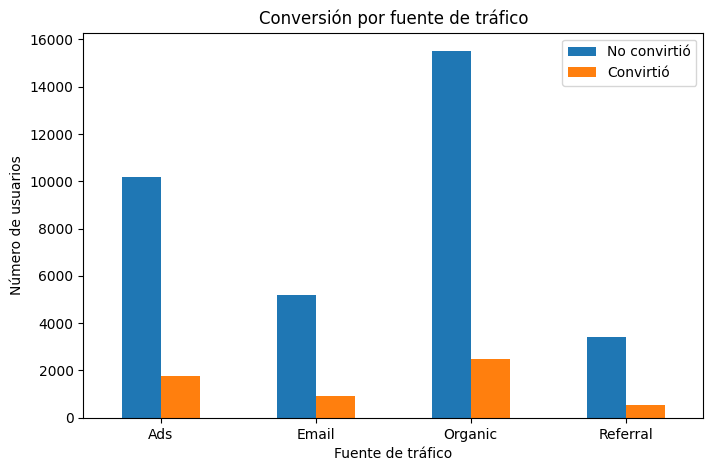

In [29]:
# Conteo de usuarios por fuente de tráfico y conversión
tabla_trafico = pd.crosstab(df["traffic_source"], df["converted"])

# Gráfico
tabla_trafico.plot(kind="bar", figsize=(8,5))

plt.title("Conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Número de usuarios")
plt.legend(["No convirtió", "Convirtió"])
plt.xticks(rotation=0)

plt.show()

✍️ **Comentario**
El gráfico muestra la cantidad de usuarios que convirtieron y no convirtieron para cada fuente de tráfico. Se observa que Organic concentra el mayor número de usuarios, por lo que también registra la mayor cantidad de conversiones en términos absolutos. Le sigue Ads, mientras que Email y Referral presentan un menor volumen de usuarios y, en consecuencia, un menor número de conversiones. En todos los canales, la cantidad de usuarios que no convierten es considerablemente mayor que la de usuarios que sí realizan una conversión.

# Gráfico 2. Porcentaje de conversión por fuente de tráfico

In [30]:
# Tabla normalizada
tabla_trafico_pct = pd.crosstab(
    df["traffic_source"],
    df["converted"],
    normalize="index"
) * 100

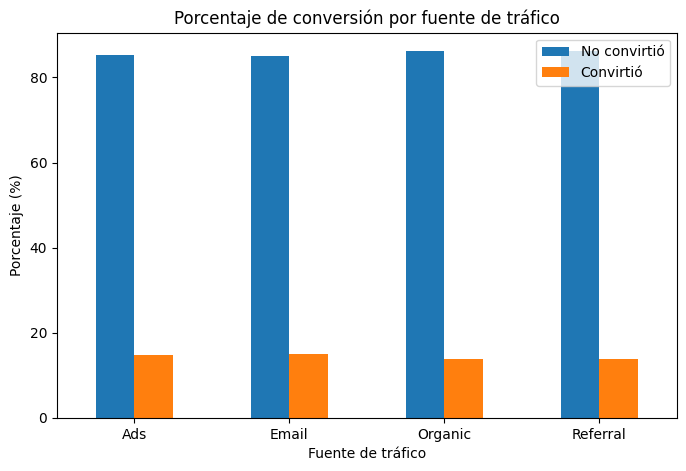

In [31]:
# Gráfico
tabla_trafico_pct.plot(kind="bar", figsize=(8,5))

plt.title("Porcentaje de conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Porcentaje (%)")
plt.legend(["No convirtió", "Convirtió"])
plt.xticks(rotation=0)

plt.show()

✍️ **Comentario**

El gráfico muestra el porcentaje de usuarios que convirtieron y no convirtieron dentro de cada fuente de tráfico. Se observa que las tasas de conversión son similares entre los distintos canales, aunque Ads y Email presentan un porcentaje de conversión ligeramente mayor que Organic y Referral. En todos los casos, la mayor parte de los usuarios no realizó una conversión, ya que el porcentaje de usuarios que no convierten supera ampliamente al de quienes sí convierten.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ ¡Excelente interpretación! Dices correctamente que "Ads y Email presentan un porcentaje de conversión ligeramente mayor que Organic y Referral" — distingues volumen de eficiencia sin cometer el error típico de este paso. Muy buen análisis.
</div>

### Relación entre el tipo de usuario y la conversión

In [32]:
# Conteo de usuarios por tipo y conversión
tabla_usuario = pd.crosstab(df["user_type"], df["converted"])

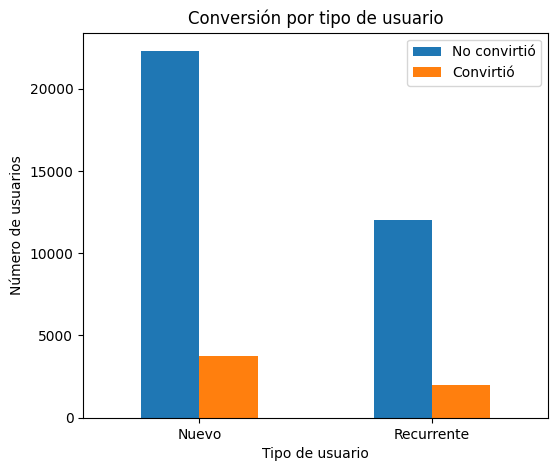

In [33]:
# Gráfico
tabla_usuario.plot(kind="bar", figsize=(6,5))

plt.title("Conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Número de usuarios")
plt.legend(["No convirtió", "Convirtió"])
plt.xticks(rotation=0)

plt.show()

✍️ **Comentario**: 
El gráfico muestra la cantidad de usuarios nuevos y recurrentes que realizaron o no una conversión. Se observa que los usuarios nuevos representan el grupo con mayor número de registros y, por ello, también presentan un mayor número de conversiones en términos absolutos. En ambos tipos de usuario, la cantidad de personas que no realizaron una conversión es considerablemente mayor que la de quienes sí convirtieron. Este gráfico permite comparar el volumen de conversiones entre ambos grupos antes de analizar sus tasas de conversión.

# Gráfico 4. Porcentaje de conversión por tipo de usuario

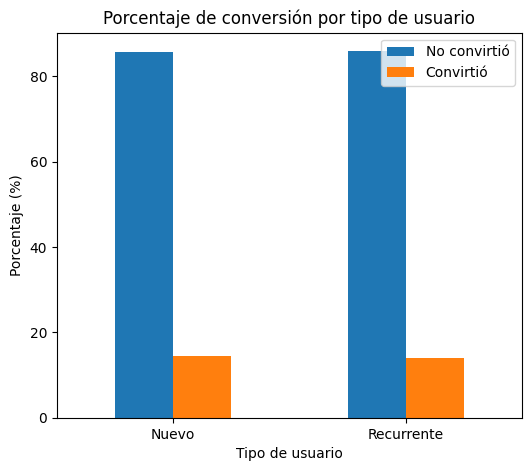

In [34]:
# Tabla normalizada
tabla_usuario_pct = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
) * 100

# Gráfico
tabla_usuario_pct.plot(kind="bar", figsize=(6,5))

plt.title("Porcentaje de conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Porcentaje (%)")
plt.legend(["No convirtió", "Convirtió"])
plt.xticks(rotation=0)

plt.show()

✍️ **Comentario**:
El gráfico muestra el porcentaje de usuarios que convirtieron y no convirtieron dentro de cada tipo de usuario. Se observa que las tasas de conversión de los usuarios nuevos y recurrentes son muy similares, con una ligera diferencia a favor de los usuarios nuevos. En ambos grupos, la mayoría de los usuarios no realizó una conversión, ya que el porcentaje de usuarios que no convierten supera ampliamente al de quienes sí convierten. Visualmente, no se aprecian diferencias importantes entre ambos tipos de usuario.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Los cuatro gráficos del Paso 6 están completos (absoluto + proporción para `traffic_source` y `user_type`). Los comentarios son correctos y coherentes con los resultados estadísticos.
</div>

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Observacion 1
La página B registró un gasto promedio de aproximadamente 68.75, mientras que la página A obtuvo un promedio de 61.09 por usuario convertido.
- Observacion 2
La prueba t de Student mostró que esta diferencia es estadísticamente significativa (valor p < 0.05), por lo que es poco probable que se deba al azar.

- **Interpretación:**
La versión B genera un mayor ingreso por usuario convertido, lo que representa una ventaja económica para el negocio.

**Tasa de conversión:** 
- Observacion 1
La página A obtuvo 2,512 conversiones de 19,982 usuarios (≈ 12.57%), mientras que la página B obtuvo 3,194 conversiones de 20,018 usuarios (≈ 15.96%).
- Observacion 2
La prueba Z para dos proporciones indicó que la diferencia en las tasas de conversión es estadísticamente significativa (valor p < 0.05).

- **Interpretación:**
La página B convierte una mayor proporción de usuarios en clientes y supera a la versión A tanto en conversión como en generación de ingresos.  

---

#### 📊 **Segmentación por fuente de tráfico**
- Observacion
La prueba de Chi-cuadrado mostró una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (p = 0.034). Además, las tasas de conversión muestran que Email (14.99%) y Ads (14.74%) presentan mejores resultados que Referral (13.88%) y Organic (13.79%).
- **Interpretación:**
El canal de adquisición influye en la probabilidad de conversión. Esto sugiere que conviene priorizar la inversión en los canales con mayores tasas de conversión y revisar estrategias para mejorar el rendimiento de los canales menos efectivos.
 ---

#### 📊 **Segmentación por tipo de usuario**
- Observacion
La prueba de Chi-cuadrado indicó que no existe una asociación estadísticamente significativa entre el tipo de usuario y la conversión (p = 0.474). Las tasas de conversión son muy similares entre usuarios nuevos (14.36%) y recurrentes (14.09%).
  
- **Interpretación:**
En este experimento, el tipo de usuario no parece influir en la probabilidad de conversión. Por ello, no existe evidencia suficiente para justificar estrategias diferenciadas únicamente con base en esta variable.
---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- Recomendación 1:
Implementar la página B como versión principal de la landing page, ya que obtuvo una mayor tasa de conversión y un mayor gasto promedio por usuario convertido, con diferencias estadísticamente significativas.

-  Recomendación 2:
Optimizar la estrategia de adquisición de usuarios enfocando una mayor inversión en los canales con mejor desempeño, como Email y Ads, y analizar oportunidades de mejora para los canales Organic y Referral. En cuanto al tipo de usuario, los resultados no justifican una segmentación específica basada únicamente en esta variable.